# NOTEBOOK 02: PHÂN TÍCH KHÁM PHÁ (EDA) & CHIA TẬP DỮ LIỆU THỐNG NHẤT
## HỆ THỐNG HỖ TRỢ HỌC TẬP LỚP 12 VIỆT NAM (CẢNH BÁO NGUY CƠ & WHAT-IF SIMULATOR)

**Bộ dữ liệu:** `data/processed/student_performance_master.csv` (6,607 học sinh x 22 cột)  
**Phạm vi áp dụng:** Học sinh lớp 12 Việt Nam  

### Mục tiêu Notebook 02:
1. **Phân tích khám phá chuyên sâu (EDA):**
   - Đánh giá phân bố nhãn nguy cơ học tập `at_risk` (< 6.5) và phân phối điểm thi cuối kỳ `Exam_Score`.
   - Khảo sát tác động của các yếu tố hoàn cảnh (Thu nhập gia đình, Tiếp cận tài liệu, Sự quan tâm của phụ huynh).
   - Đo lường tương quan giữa các hành vi có thể thay đổi (`Hours_Studied`, `Attendance`, `effective_study_index`) với kết quả học tập.
   - Nhận diện "Vùng nguy cơ" (Risk Zone) trên không gian hành vi học tập.
   - Xuất 4 biểu đồ chuẩn xuất bản ở độ phân giải cao 300 DPI vào `reports/figures/`.
2. **Chia tập dữ liệu thống nhất (Unified Stratified Splitting):**
   - Áp dụng phân tầng (`stratify=at_risk`) để chia tập: **70% Train** (4,624), **15% Dev** (991), **15% Test** (992).
   - Tiếp tục tách tập Dev thành **70% Dev Blackbox** (693 - để chọn thuật toán & tune threshold) và **30% Dev Eyeball** (298 - để phân tích lỗi định tính).
   - **Nguyên tắc kỹ thuật sống còn:** Cả 2 tầng (Tầng 1: Phân loại, Tầng 2: Hồi quy) dùng chung một lần split duy nhất để chống rò rỉ dữ liệu (Anti-Leakage) và đồng bộ index.

---
## 📊 EPIC 2: PHÂN TÍCH KHÁM PHÁ (EDA)
### 🔹 Task 2.1: Vẽ 4 Biểu đồ EDA Cốt lõi cho Học sinh Lớp 12 & Xuất file 300 DPI

In [1]:
# CELL 1: Import thư viện và thiết lập hiển thị đồ họa
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình đường dẫn
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
PROCESSED_FILE = os.path.join(PROJECT_ROOT, 'data', 'processed', 'student_performance_master.csv')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# Thiết lập phong cách hiển thị biểu đồ
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11

df = pd.read_csv(PROCESSED_FILE)
print(f"✅ Đã nạp thành công Master Dataset: {df.shape[0]:,} dòng x {df.shape[1]} cột.")

✅ Đã nạp thành công Master Dataset: 6,607 dòng x 22 cột.


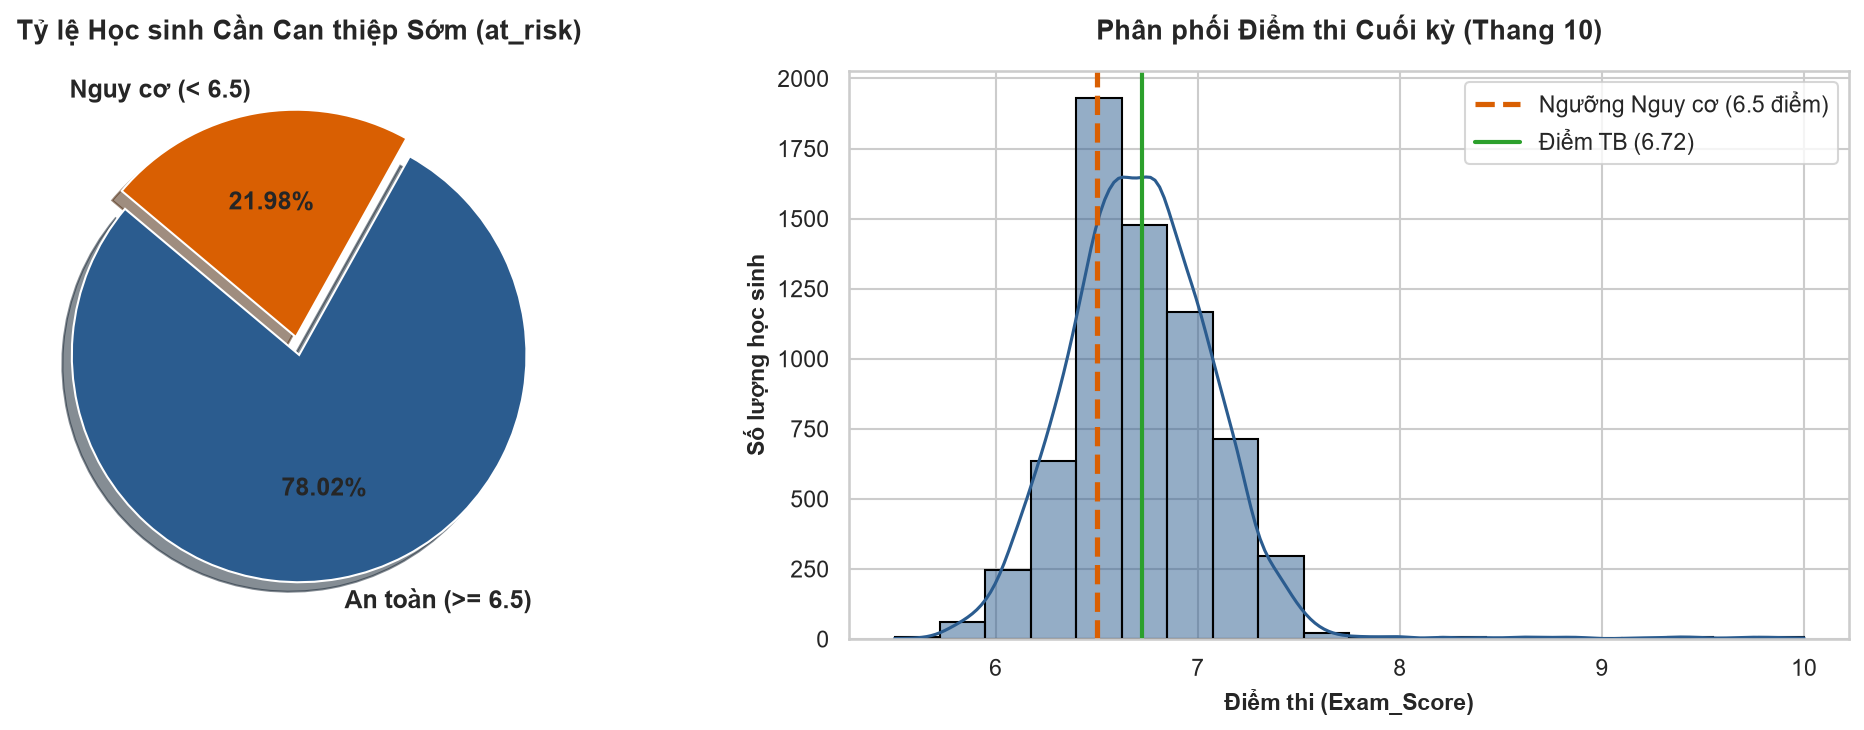

💾 Đã lưu Biểu đồ 1: D:\What-If Simulator\reports\figures\fig1_at_risk_and_score_distribution.png


In [2]:
# CELL 2: Biểu đồ 1 — Phân bố Nhãn Nguy cơ at_risk & Phân phối Điểm thi Exam_Score (thang 10)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1.1 Tỷ lệ học sinh An toàn vs Nguy cơ
risk_counts = df['at_risk'].value_counts()
colors = ['#2b5c8f', '#d95f02']
labels = ['An toàn (>= 6.5)', 'Nguy cơ (< 6.5)']
axes[0].pie(
    risk_counts, labels=labels, autopct='%1.2f%%', startangle=140,
    colors=colors, explode=(0, 0.08), shadow=True,
    textprops={'fontsize': 12, 'weight': 'bold'}
)
axes[0].set_title("Tỷ lệ Học sinh Cần Can thiệp Sớm (at_risk)", fontsize=13, weight='bold', pad=15)

# 1.2 Phân phối điểm thi Exam_Score
sns.histplot(df['Exam_Score'], bins=20, kde=True, ax=axes[1], color='#2b5c8f', edgecolor='black')
axes[1].axvline(6.5, color='#d95f02', linestyle='--', linewidth=2.5, label='Ngưỡng Nguy cơ (6.5 điểm)')
axes[1].axvline(df['Exam_Score'].mean(), color='#2ca02c', linestyle='-', linewidth=2, label=f"Điểm TB ({df['Exam_Score'].mean():.2f})")
axes[1].set_title("Phân phối Điểm thi Cuối kỳ (Thang 10)", fontsize=13, weight='bold', pad=15)
axes[1].set_xlabel("Điểm thi (Exam_Score)", fontsize=11, weight='bold')
axes[1].set_ylabel("Số lượng học sinh", fontsize=11, weight='bold')
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
fig1_path = os.path.join(FIGURES_DIR, 'fig1_at_risk_and_score_distribution.png')
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 1: {fig1_path}")

C:\Users\Giavy\AppData\Local\Temp\ipykernel_29020\1577309765.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Giavy\AppData\Local\Temp\ipykernel_29020\1577309765.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


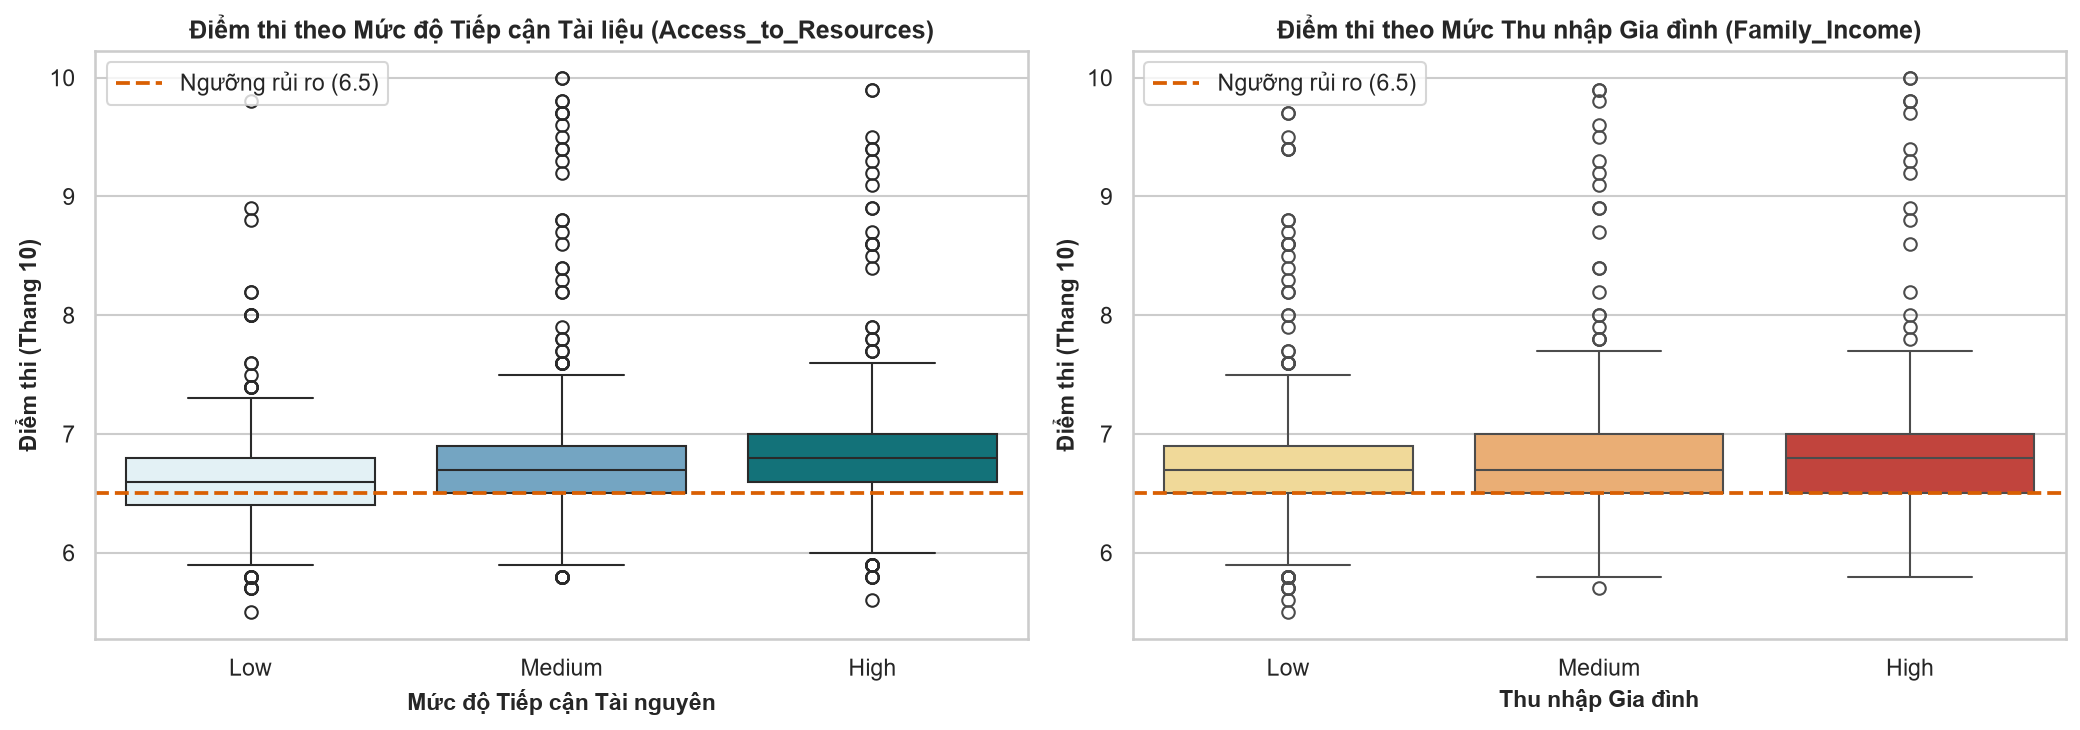

💾 Đã lưu Biểu đồ 2: D:\What-If Simulator\reports\figures\fig2_context_factors_impact.png


In [3]:
# CELL 3: Biểu đồ 2 — Tác động của các Yếu tố Hoàn cảnh (Tài nguyên & Thu nhập) lên Điểm thi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_levels = ['Low', 'Medium', 'High']

# 2.1 Tiếp cận tài nguyên học tập vs Điểm thi
sns.boxplot(
    data=df, x='Access_to_Resources', y='Exam_Score', order=order_levels,
    palette=['#e0f3f8', '#67a9cf', '#02818a'], ax=axes[0]
)
axes[0].axhline(6.5, color='#d95f02', linestyle='--', linewidth=1.8, label='Ngưỡng rủi ro (6.5)')
axes[0].set_title("Điểm thi theo Mức độ Tiếp cận Tài liệu (Access_to_Resources)", fontsize=12, weight='bold')
axes[0].set_xlabel("Mức độ Tiếp cận Tài nguyên", fontsize=11, weight='bold')
axes[0].set_ylabel("Điểm thi (Thang 10)", fontsize=11, weight='bold')
axes[0].legend(loc='upper left')

# 2.2 Thu nhập gia đình vs Điểm thi
sns.boxplot(
    data=df, x='Family_Income', y='Exam_Score', order=order_levels,
    palette=['#fee08b', '#fdae61', '#d73027'], ax=axes[1]
)
axes[1].axhline(6.5, color='#d95f02', linestyle='--', linewidth=1.8, label='Ngưỡng rủi ro (6.5)')
axes[1].set_title("Điểm thi theo Mức Thu nhập Gia đình (Family_Income)", fontsize=12, weight='bold')
axes[1].set_xlabel("Thu nhập Gia đình", fontsize=11, weight='bold')
axes[1].set_ylabel("Điểm thi (Thang 10)", fontsize=11, weight='bold')
axes[1].legend(loc='upper left')

plt.tight_layout()
fig2_path = os.path.join(FIGURES_DIR, 'fig2_context_factors_impact.png')
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 2: {fig2_path}")

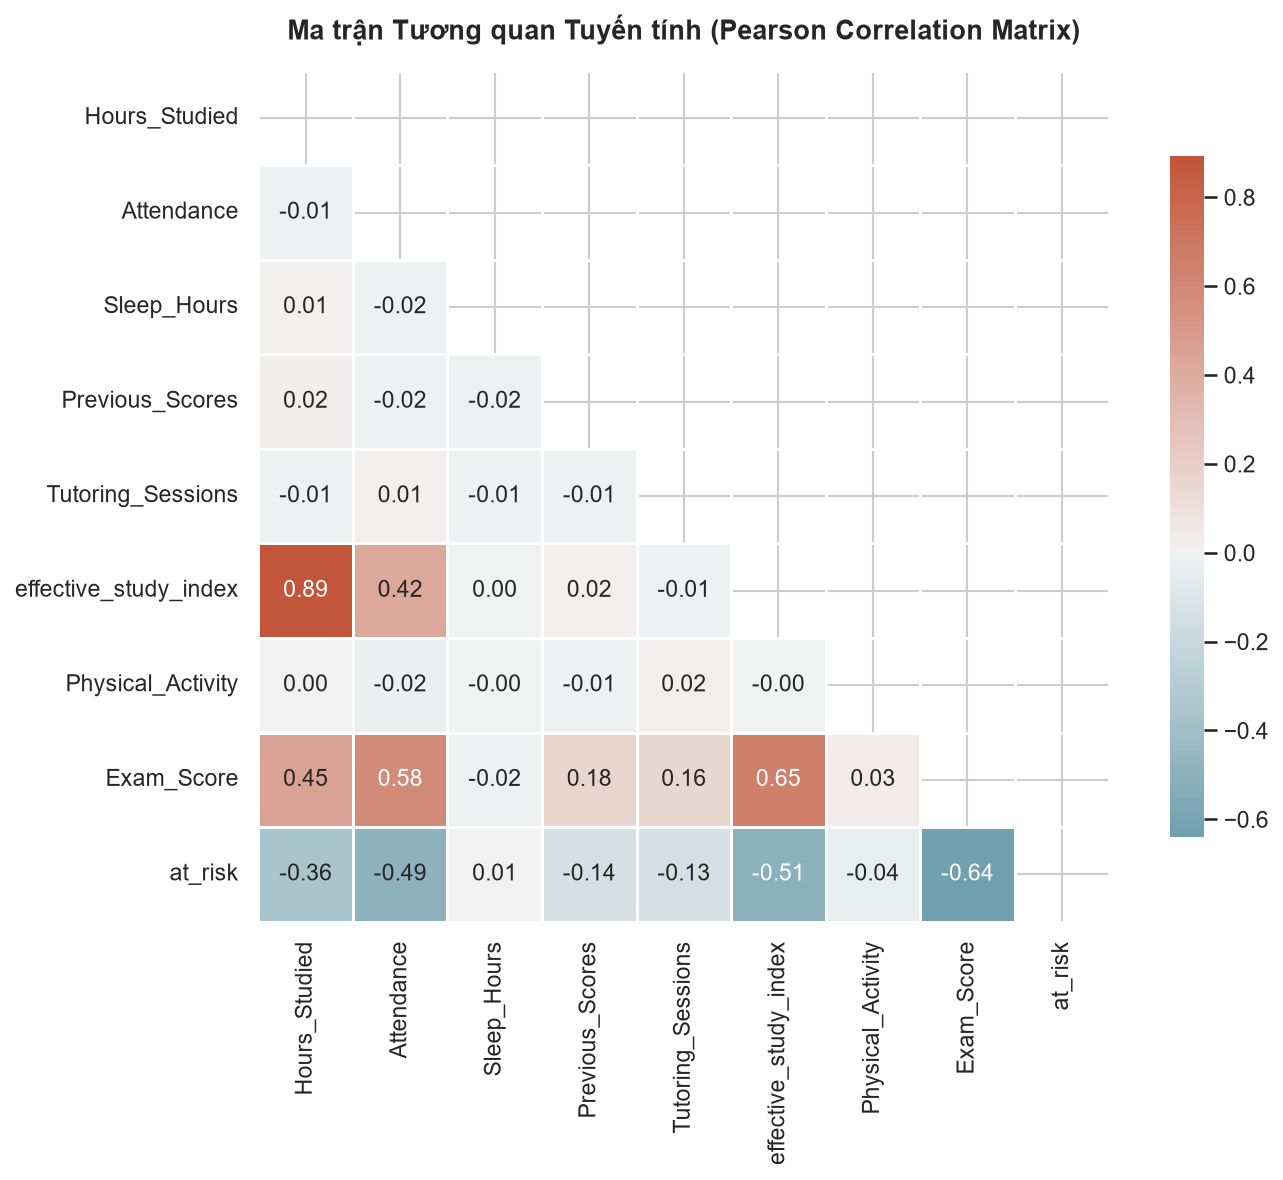

💾 Đã lưu Biểu đồ 3: D:\What-If Simulator\reports\figures\fig3_correlation_heatmap.png


In [4]:
# CELL 4: Biểu đồ 3 — Heatmap Ma trận Tương quan giữa các Biến Định lượng & Kết quả Học tập
numeric_cols = [
    'Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
    'Tutoring_Sessions', 'effective_study_index', 'Physical_Activity',
    'Exam_Score', 'at_risk'
]

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(220, 20, as_cmap=True)

sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap=cmap,
    center=0, square=True, linewidths=.5, cbar_kws={"shrink": .8}
)
plt.title("Ma trận Tương quan Tuyến tính (Pearson Correlation Matrix)", fontsize=13, weight='bold', pad=15)

plt.tight_layout()
fig3_path = os.path.join(FIGURES_DIR, 'fig3_correlation_heatmap.png')
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 3: {fig3_path}")

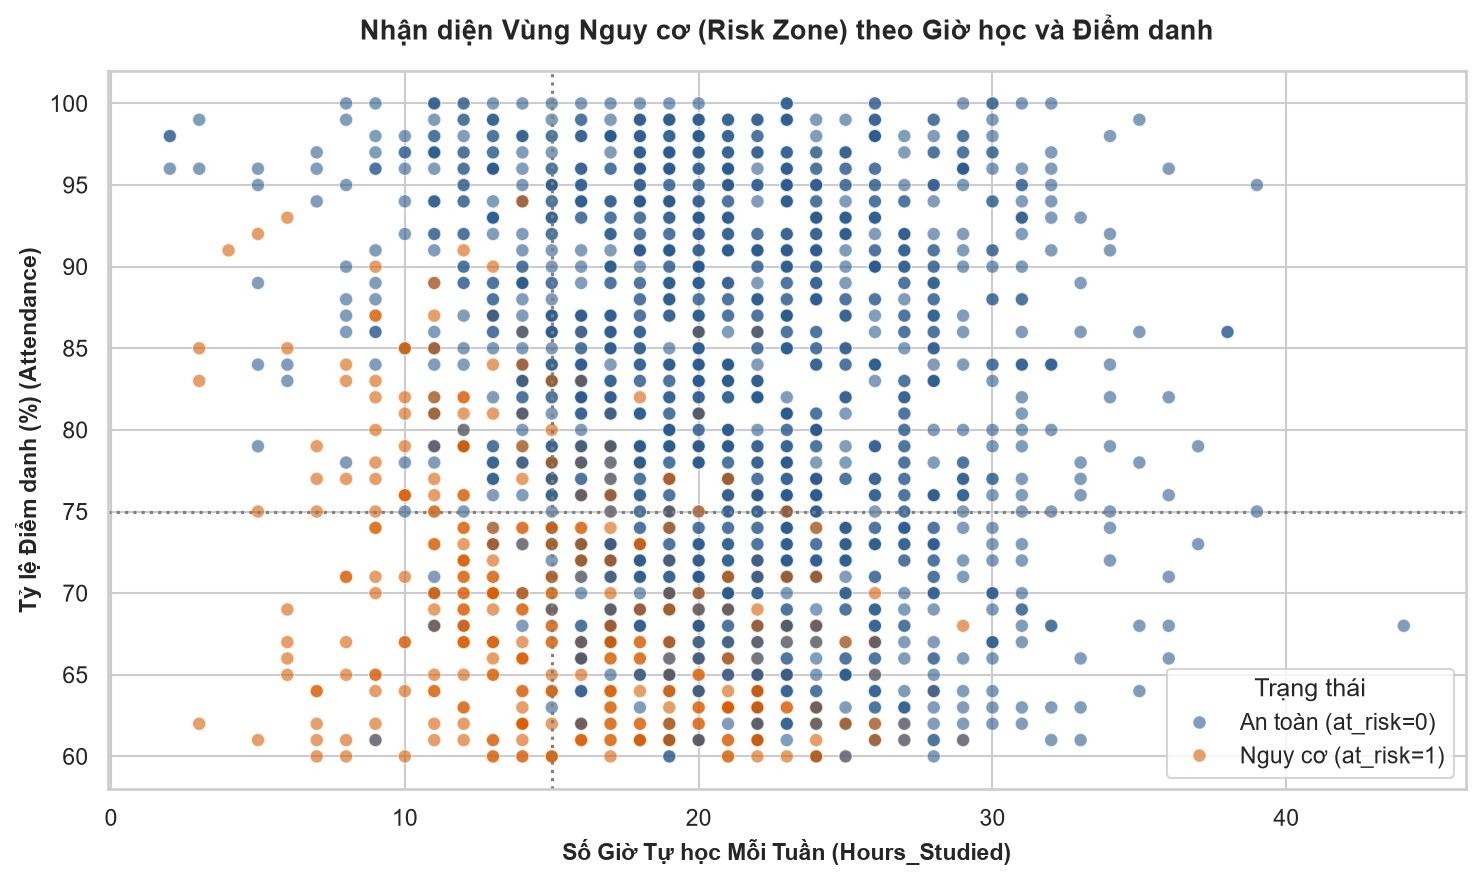

💾 Đã lưu Biểu đồ 4: D:\What-If Simulator\reports\figures\fig4_actionable_behaviors_risk_zone.png


In [5]:
# CELL 5: Biểu đồ 4 — Phân tích Vùng Nguy cơ (Risk Zone) trên Không gian Hành vi Học tập
plt.figure(figsize=(10, 6))

scatter = sns.scatterplot(
    data=df.sample(2000, random_state=42),  # Lấy mẫu 2000 điểm để hiển thị rõ mật độ
    x='Hours_Studied', y='Attendance', hue='at_risk',
    palette={0: '#2b5c8f', 1: '#d95f02'}, alpha=0.6, s=40
)

# Vạch vùng nguy cơ trực quan cho GV và PH
plt.axvline(15, color='gray', linestyle=':', linewidth=1.5, label='Mốc 15 giờ học/tuần')
plt.axhline(75, color='gray', linestyle=':', linewidth=1.5, label='Mốc 75% Chuyên cần')

plt.title("Nhận diện Vùng Nguy cơ (Risk Zone) theo Giờ học và Điểm danh", fontsize=13, weight='bold', pad=15)
plt.xlabel("Số Giờ Tự học Mỗi Tuần (Hours_Studied)", fontsize=11, weight='bold')
plt.ylabel("Tỷ lệ Điểm danh (%) (Attendance)", fontsize=11, weight='bold')

handles, labels = scatter.get_legend_handles_labels()
plt.legend(
    handles=handles[:2], labels=['An toàn (at_risk=0)', 'Nguy cơ (at_risk=1)'],
    title="Trạng thái", loc='lower right', frameon=True
)

plt.tight_layout()
fig4_path = os.path.join(FIGURES_DIR, 'fig4_actionable_behaviors_risk_zone.png')
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 4: {fig4_path}")

---
## 📦 EPIC 2: TÁCH TẬP DỮ LIỆU (DATA SPLITTING)
### 🔹 Task 2.2: Chia tập Train (70%) / Dev (15%) / Test (15%) Thống nhất cho Cả 2 Tầng

**Yêu cầu kỹ thuật:**
1. **Phân tầng (Stratified Splitting):** Dùng `stratify=at_risk` để giữ nguyên tỷ lệ nhãn ~22.0% ở cả 3 tập.
2. **Bảo mật Tập Test (Anti-Leakage):** Tập Test (15% = 992 dòng) được niêm phong hoàn toàn, chỉ dùng để đánh giá cuối cùng.
3. **Phân chia Dev:** Tập Dev (15% = 991 dòng) được tách thành:
   - **Dev Blackbox (70% = 693 dòng):** Đánh giá khách quan các mô hình và tune threshold.
   - **Dev Eyeball (30% = 298 dòng):** Phân tích lỗi định tính mẫu cụ thể (Error Analysis).
4. **Đồng bộ 2 tầng:** Cả Tầng 1 và Tầng 2 đều dùng chung bộ index này.

In [6]:
# CELL 6: Thực hiện Stratified Splitting 70/15/15 và Tách Dev Blackbox/Eyeball
from sklearn.model_selection import train_test_split

SPLITS_DIR = os.path.join(PROJECT_ROOT, 'data', 'splits')
os.makedirs(SPLITS_DIR, exist_ok=True)

# Bước 1: Tách 70% Train và 30% Temp (stratify theo nhãn at_risk)
train_idx, temp_idx = train_test_split(
    df.index, test_size=0.30, random_state=42, stratify=df['at_risk']
)

# Bước 2: Chia đôi 30% Temp thành 15% Dev và 15% Test (stratify theo at_risk)
dev_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=42, stratify=df.loc[temp_idx, 'at_risk']
)

# Bước 3: Tách 15% Dev thành 70% Dev Blackbox và 30% Dev Eyeball (stratify theo at_risk)
dev_bb_idx, dev_eye_idx = train_test_split(
    dev_idx, test_size=0.30, random_state=42, stratify=df.loc[dev_idx, 'at_risk']
)

# Tạo các DataFrame con
df_train       = df.loc[train_idx].copy()
df_dev         = df.loc[dev_idx].copy()
df_dev_bb      = df.loc[dev_bb_idx].copy()
df_dev_eye     = df.loc[dev_eye_idx].copy()
df_test        = df.loc[test_idx].copy()

# Lưu các file split chuẩn vào data/splits/
df_train.to_csv(os.path.join(SPLITS_DIR, 'train.csv'), index=False)
df_dev.to_csv(os.path.join(SPLITS_DIR, 'dev.csv'), index=False)
df_dev_bb.to_csv(os.path.join(SPLITS_DIR, 'dev_blackbox.csv'), index=False)
df_dev_eye.to_csv(os.path.join(SPLITS_DIR, 'dev_eyeball.csv'), index=False)
df_test.to_csv(os.path.join(SPLITS_DIR, 'test.csv'), index=False)

# Lưu cả tên stage2_... để tương thích ngược 100% với các script hiện có
df_train.to_csv(os.path.join(SPLITS_DIR, 'stage2_train.csv'), index=False)
df_dev.to_csv(os.path.join(SPLITS_DIR, 'stage2_dev.csv'), index=False)
df_dev_bb.to_csv(os.path.join(SPLITS_DIR, 'stage2_dev_blackbox.csv'), index=False)
df_dev_eye.to_csv(os.path.join(SPLITS_DIR, 'stage2_dev_eyeball.csv'), index=False)
df_test.to_csv(os.path.join(SPLITS_DIR, 'stage2_test.csv'), index=False)

# Lưu cả tên stage1_... để các notebook baseline cũ hoặc mới dùng được ngay
df_train.to_csv(os.path.join(SPLITS_DIR, 'stage1_train.csv'), index=False)
df_dev.to_csv(os.path.join(SPLITS_DIR, 'stage1_dev.csv'), index=False)
df_dev_bb.to_csv(os.path.join(SPLITS_DIR, 'stage1_dev_blackbox.csv'), index=False)
df_dev_eye.to_csv(os.path.join(SPLITS_DIR, 'stage1_dev_eyeball.csv'), index=False)
df_test.to_csv(os.path.join(SPLITS_DIR, 'stage1_test.csv'), index=False)

# ============================================================
# CHECKPOINTS KIỂM ĐỊNH CHẤT LƯỢNG (ACCEPTANCE CRITERIA)
# ============================================================
assert len(df_train) == 4624, f"❌ Lỗi: Train không đủ 4624 dòng ({len(df_train)})!"
assert len(df_dev)   == 991,  f"❌ Lỗi: Dev không đủ 991 dòng ({len(df_dev)})!"
assert len(df_dev_bb)== 693,  f"❌ Lỗi: Dev BB không đủ 693 dòng ({len(df_dev_bb)})!"
assert len(df_dev_eye)== 298, f"❌ Lỗi: Dev Eye không đủ 298 dòng ({len(df_dev_eye)})!"
assert len(df_test)  == 992,  f"❌ Lỗi: Test không đủ 992 dòng ({len(df_test)})!"

# Kiểm tra chống trùng lặp hoàn toàn giữa các tập
assert len(set(train_idx).intersection(set(dev_idx))) == 0, "❌ Lỗi: Rò rỉ giữa Train và Dev!"
assert len(set(train_idx).intersection(set(test_idx))) == 0, "❌ Lỗi: Rò rỉ giữa Train và Test!"
assert len(set(dev_idx).intersection(set(test_idx))) == 0, "❌ Lỗi: Rò rỉ giữa Dev và Test!"

# Kiểm tra tính đồng đều của phân bố nhãn at_risk và Exam_Score
train_risk_rate = df_train['at_risk'].mean()
dev_risk_rate   = df_dev['at_risk'].mean()
test_risk_rate  = df_test['at_risk'].mean()

assert abs(train_risk_rate - 0.2198) < 0.01, "❌ Lỗi: Phân bố nhãn Train lệch quá mức!"
assert abs(dev_risk_rate   - 0.2198) < 0.01, "❌ Lỗi: Phân bố nhãn Dev lệch quá mức!"
assert abs(test_risk_rate  - 0.2198) < 0.01, "❌ Lỗi: Phân bố nhãn Test lệch quá mức!"

print("="*65)
print("🎉 TASK 2.2 CHECKPOINTS: TẤT CẢ TIÊU CHÍ ĐỀU ĐẠT CHUẨN XUẤT SẮC!")
print(f"   📦 Train (70%):            {len(df_train):,} dòng | Tỷ lệ nguy cơ: {train_risk_rate*100:.2f}% | Điểm TB: {df_train['Exam_Score'].mean():.2f}/10")
print(f"   📦 Dev Tổng (15%):         {len(df_dev):,} dòng | Tỷ lệ nguy cơ: {dev_risk_rate*100:.2f}% | Điểm TB: {df_dev['Exam_Score'].mean():.2f}/10")
print(f"      🔹 Dev Blackbox (70%):  {len(df_dev_bb):,} dòng | Tỷ lệ nguy cơ: {df_dev_bb['at_risk'].mean()*100:.2f}%")
print(f"      🔹 Dev Eyeball (30%):   {len(df_dev_eye):,} dòng | Tỷ lệ nguy cơ: {df_dev_eye['at_risk'].mean()*100:.2f}%")
print(f"   📦 Test (15%):             {len(df_test):,} dòng | Tỷ lệ nguy cơ: {test_risk_rate*100:.2f}% | Điểm TB: {df_test['Exam_Score'].mean():.2f}/10")
print("="*65)
print("\n🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% EPIC 2 (NOTEBOOK 02)! 🏆")

🎉 TASK 2.2 CHECKPOINTS: TẤT CẢ TIÊU CHÍ ĐỀU ĐẠT CHUẨN XUẤT SẮC!
   📦 Train (70%):            4,624 dòng | Tỷ lệ nguy cơ: 21.97% | Điểm TB: 6.72/10
   📦 Dev Tổng (15%):         991 dòng | Tỷ lệ nguy cơ: 22.00% | Điểm TB: 6.73/10
      🔹 Dev Blackbox (70%):  693 dòng | Tỷ lệ nguy cơ: 21.93%
      🔹 Dev Eyeball (30%):   298 dòng | Tỷ lệ nguy cơ: 22.15%
   📦 Test (15%):             992 dòng | Tỷ lệ nguy cơ: 21.98% | Điểm TB: 6.74/10

🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% EPIC 2 (NOTEBOOK 02)! 🏆
